# Benchmark comparativo de algoritmos evolutivos y metaheurísticos

In [1]:
import math
import json

from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import friedmanchisquare

In [2]:
class Problem(ABC):

    @abstractmethod
    def validate(self, candidate):
        pass

    @abstractmethod
    def evaluate(self, candidate):
        pass

    @abstractmethod
    def random_solution(self, rng):
        pass

In [3]:
class ContinuousProblem(Problem):
    def __init__(self, dimension, lower_bound, upper_bound):
        self.dimension = dimension
        self.lower_bound = lower_bound
        self.upper_bound = upper_bound

    def validate(self, candidate):
        if len(candidate) != self.dimension:
            return False

        for x in candidate:
            if not (self.lower_bound <= x <= self.upper_bound):
                return False

        return True

In [4]:
class Sphere(ContinuousProblem):

    def evaluate(self, candidate):
        result = 0.0

        for x in candidate:
            result += x ** 2

        return result

    def random_solution(self, rng):
        return rng.uniform(
            self.lower_bound,
            self.upper_bound,
            size=self.dimension
        )

In [5]:
class Rastrigin(ContinuousProblem):

    def evaluate(self, candidate):
        result = 10 * self.dimension

        for x in candidate:
            result += x ** 2 - 10 * math.cos(2 * math.pi * x)

        return result

    def random_solution(self, rng):
        return rng.uniform(
            self.lower_bound,
            self.upper_bound,
            size=self.dimension
        )

In [6]:
class TSP(Problem):

    def __init__(self, cities):
        self.cities = cities

    def validate(self, candidate):
        return (
            len(candidate) == len(self.cities)
            and all(
                isinstance(x, (int, np.integer))
                and not isinstance(x, (bool, np.bool_))
                for x in candidate
            )
            and set(candidate) == set(range(len(self.cities)))
        )

    def evaluate(self, candidate):
        if not self.validate(candidate):
            raise ValueError("Invalid TSP tour")

        distance = 0.0

        for i in range(len(candidate)):
            current_index = candidate[i]
            next_index = candidate[(i + 1) % len(candidate)]

            distance += np.linalg.norm(
                self.cities[current_index]
                - self.cities[next_index]
            )

        return distance

    def random_solution(self, rng):
        return rng.permutation(len(self.cities))


def create_tsp_instance():
    rng = np.random.default_rng(314159)
    cities = rng.uniform(0, 100, size=(20, 2))
    return TSP(cities)

In [7]:
def tsp_edge_distance(route_a, route_b):
    edges_a = set()
    edges_b = set()

    for i in range(len(route_a)):
        city = route_a[i]
        next_city = route_a[(i + 1) % len(route_a)]
        edge = frozenset([city, next_city])
        edges_a.add(edge)

    for i in range(len(route_b)):
        city = route_b[i]
        next_city = route_b[(i + 1) % len(route_b)]
        edge = frozenset([city, next_city])
        edges_b.add(edge)

    common_edges = edges_a.intersection(edges_b)
    return 1 - len(common_edges) / len(route_a)


def tsp_population_diversity(population):
    total_distance = 0

    for i in range(len(population)):
        for j in range(i + 1, len(population)):
            total_distance += tsp_edge_distance(
                population[i], population[j]
            )

    n = len(population)
    num_pairs = n * (n - 1) / 2
    return total_distance / num_pairs


def continuous_solution_diversity(solutions, lower_bound, upper_bound):
    total_distance = 0
    n = len(solutions)

    if n < 2:
        return 0

    dimension = len(solutions[0])
    max_distance = np.sqrt(dimension) * (upper_bound - lower_bound)

    for i in range(len(solutions)):
        for j in range(i + 1, len(solutions)):
            x = solutions[i]
            y = solutions[j]

            distance = np.linalg.norm(x - y)

            total_distance += (
                distance / max_distance
                if max_distance > 0 else 0.0
            )

    num_pairs = n * (n - 1) / 2
    return total_distance / num_pairs

In [8]:
def evaluations_to_convergence(best_history, patience=1000):
    last_improvement = 1

    for i in range(1, len(best_history)):
        if best_history[i] < best_history[i - 1]:
            last_improvement = i + 1

    evaluations_without_improvement = len(best_history) - last_improvement

    if evaluations_without_improvement >= patience:
        return last_improvement + patience

    return None

In [9]:
class Evaluator:
    def __init__(self, problem, max_evaluations):
        if type(max_evaluations) is not int:
            raise TypeError("max_evaluations must be an integer")

        if max_evaluations <= 0:
            raise ValueError("Evaluation budget must be positive")

        self.problem = problem
        self.max_evaluations = max_evaluations
        self.evaluations = 0
        self.best_fitness = float("inf")
        self.best_history = []
        self.diversity_history = []
        self.best_candidate = None

    def evaluate(self, candidate):
        if self.evaluations >= self.max_evaluations:
            raise RuntimeError("Evaluation budget exhausted")

        result = self.problem.evaluate(candidate)
        self.evaluations += 1

        if not math.isfinite(result):
            raise ValueError("Fitness must be finite")

        if result < self.best_fitness:
            self.best_fitness = result
            self.best_candidate = deepcopy(candidate)

        self.best_history.append(self.best_fitness)

        return result

    def record_diversity(self, diversity):
        self.diversity_history.append(
            (self.evaluations, diversity)
        )

In [10]:
@dataclass
class RunResult:
    algorithm: str
    problem: str
    seed: int
    best_fitness: float
    evaluations: int
    best_history: tuple[float, ...]
    diversity_history: tuple[tuple[int, float], ...] = ()
    best_candidate: tuple[int | float, ...] | None = None

    def __post_init__(self):
        if self.evaluations <= 0:
            raise ValueError("Evaluation count must be positive")

        if len(self.best_history) != self.evaluations:
            raise ValueError(
                "History length must match evaluation count"
            )

        if self.best_fitness != self.best_history[-1]:
            raise ValueError(
                "Best fitness must match final history value"
            )

In [11]:
class ExperimentRunner:
    def __init__(self, max_evaluations):
        self.max_evaluations = max_evaluations

    def run(self, algorithm, problem, seed):
        rng = np.random.default_rng(seed)
        evaluator = Evaluator(problem, self.max_evaluations)

        algorithm.run(problem, evaluator, rng)

        result = RunResult(
            algorithm=type(algorithm).__name__,
            problem=type(problem).__name__,
            seed=seed,
            best_fitness=evaluator.best_fitness,
            evaluations=evaluator.evaluations,
            best_history=tuple(evaluator.best_history),
            diversity_history=tuple(evaluator.diversity_history),
            best_candidate=tuple(evaluator.best_candidate)
        )

        return result

In [12]:
class GeneticAlgorithm:
    def __init__(self, population_size):
        if not isinstance(population_size, int) or isinstance(population_size, bool):
            raise TypeError("population_size must be an integer")
        if population_size < 3:
            raise ValueError("population_size must be >= 3")
        self.population_size = population_size

    def run(self, problem, evaluator, rng):
        if evaluator.max_evaluations < self.population_size:
            raise ValueError("Evaluation budget is smaller than population size")
        if not isinstance(problem, (TSP, ContinuousProblem)):
            raise TypeError("problem must be an instance of TSP or ContinuousProblem")

        population = []
        fitness_values = []

        for _ in range(0, self.population_size):
            candidate = problem.random_solution(rng)
            fitness = evaluator.evaluate(candidate)
            population.append(candidate)
            fitness_values.append(fitness)

        while evaluator.evaluations < evaluator.max_evaluations:
            best_index = min(
                range(len(population)),
                key=lambda i: fitness_values[i]
            )
            new_population = [population[best_index].copy()]
            new_fitness_values = [fitness_values[best_index]]

            while (
                len(new_population) < self.population_size
                and evaluator.evaluations < evaluator.max_evaluations
            ):
                index_1 = self._tournament_select(fitness_values, rng)
                index_2 = self._tournament_select(fitness_values, rng)

                parent_a = population[index_1]
                parent_b = population[index_2]

                if rng.random() < 0.9:
                    if isinstance(problem, TSP):
                        child = self._order_crossover(parent_a, parent_b, rng)
                    else:
                        child = self._arithmetic_crossover(parent_a, parent_b, rng)
                else:
                    child = parent_a.copy()

                if isinstance(problem, TSP):
                    mutated = self._swap_mutation(child, rng)
                else:
                    mutated = self._gaussian_mutation(child, problem, rng)

                fitness = evaluator.evaluate(mutated)

                new_population.append(mutated)
                new_fitness_values.append(fitness)

            population = new_population
            fitness_values = new_fitness_values

    def _tournament_select(self, fitness_values, rng):
        indices = rng.choice(
            len(fitness_values),
            size=3,
            replace=False
        )
        return min(indices, key=lambda x: fitness_values[x])

    def _arithmetic_crossover(self, parent_a, parent_b, rng):
        alpha = rng.random()
        return parent_a * alpha + parent_b * (1 - alpha)

    def _gaussian_mutation(self, candidate, problem, rng):
        sigma = 0.1 * (problem.upper_bound - problem.lower_bound)
        noise = rng.normal(
            loc=0.0,
            scale=sigma,
            size=len(candidate)
        )
        mutation_probability = 1.0 / len(candidate)
        mask = rng.random(size=len(candidate)) < mutation_probability
        masked_noise = noise * mask
        mutated_candidate = candidate + masked_noise

        return np.clip(
            mutated_candidate,
            problem.lower_bound,
            problem.upper_bound
        )

    def _order_crossover(self, parent_a, parent_b, rng):
        cuts = rng.choice(
            len(parent_a),
            size=2,
            replace=False
        )
        left, right = sorted(cuts)

        child = np.full(len(parent_a), -1, dtype=int)
        child[left:right + 1] = parent_a[left:right + 1]

        write_index = (right + 1) % len(parent_a)

        for i in range(len(parent_a)):
            index = (right + 1 + i) % len(parent_a)
            city = parent_b[index]

            if city not in child:
                child[write_index] = city
                write_index = (write_index + 1) % len(parent_a)

        return child

    def _swap_mutation(self, candidate, rng):
        swapped = candidate.copy()
        a, b = rng.choice(
            len(candidate),
            size=2,
            replace=False
        )
        swapped[a], swapped[b] = swapped[b], swapped[a]
        return swapped

In [13]:
class EvolutionStrategy:
    def __init__(self, mu, offspring_size):
        if not isinstance(mu, int) or isinstance(mu, bool):
            raise TypeError("mu must be integer")
        if mu < 1:
            raise ValueError("mu must be >= 1")

        if not isinstance(offspring_size, int) or isinstance(offspring_size, bool):
            raise TypeError("offspring_size must be an integer")
        if offspring_size < 1:
            raise ValueError("offspring_size must be >= 1")

        self.mu = mu
        self.offspring_size = offspring_size

    def run(self, problem, evaluator, rng):

        if not isinstance(problem, TSP) and not isinstance(problem, ContinuousProblem):
            raise TypeError("problem must be TSP or ContinuousProblem")

        if evaluator.max_evaluations < self.mu:
            raise ValueError("Evaluation budget is smaller than mu")

        population = []
        fitness_values = []

        for _ in range(self.mu):
            candidate = problem.random_solution(rng)
            fitness = evaluator.evaluate(candidate)

            population.append(candidate)
            fitness_values.append(fitness)

        while evaluator.evaluations < evaluator.max_evaluations:
            offspring = []
            offspring_fitness = []

            for _ in range(self.offspring_size):
                if evaluator.evaluations >= evaluator.max_evaluations:
                    break

                parent_index = rng.integers(len(population))
                parent = population[parent_index]

                if isinstance(problem, TSP):
                    child = self._swap_mutation(parent, rng)
                else:
                    child = self._gaussian_mutation(parent, problem, rng)

                fitness = evaluator.evaluate(child)

                offspring.append(child)
                offspring_fitness.append(fitness)

            combined_population = population + offspring
            combined_fitness = fitness_values + offspring_fitness

            population, fitness_values = self._select_survivors(
                combined_population,
                combined_fitness
            )

    def _gaussian_mutation(self, parent, problem, rng):
        sigma = 0.1 * (problem.upper_bound - problem.lower_bound)
        noise = rng.normal(
            loc=0.0,
            scale=sigma,
            size=len(parent)
        )

        child = parent + noise

        return np.clip(
            child,
            problem.lower_bound,
            problem.upper_bound
        )

    def _select_survivors(self, combined_population, combined_fitness):
        sorted_indices = sorted(
            range(len(combined_population)),
            key=lambda i: combined_fitness[i]
        )

        best_indices = sorted_indices[:self.mu]

        survivors = [combined_population[i] for i in best_indices]
        survivor_fitness = [combined_fitness[i] for i in best_indices]

        return survivors, survivor_fitness

    def _swap_mutation(self, parent, rng):
        mutated = parent.copy()
        a, b = rng.choice(
            len(parent),
            size=2,
            replace=False
        )
        mutated[a], mutated[b] = mutated[b], mutated[a]
        return mutated

In [14]:
class HillClimbing:
    def __init__(self):
        pass

    def run(self, problem, evaluator, rng):
        if not isinstance(problem, (ContinuousProblem, TSP)):
            raise TypeError("problem must be Continuous or TSP")

        current = problem.random_solution(rng)
        current_fitness = evaluator.evaluate(current)

        while evaluator.evaluations < evaluator.max_evaluations:
            neighbor = self._generate_neighbor(current, problem, rng)
            neighbor_fitness = evaluator.evaluate(neighbor)

            if neighbor_fitness < current_fitness:
                current = neighbor
                current_fitness = neighbor_fitness

    def _gaussian_neighbor(self, current, problem, rng):
        sigma = 0.1 * (problem.upper_bound - problem.lower_bound)

        neighbor = current + rng.normal(
            loc=0.0,
            scale=sigma,
            size=len(current)
        )

        return np.clip(
            neighbor,
            problem.lower_bound,
            problem.upper_bound
        )

    def _generate_neighbor(self, current, problem, rng):
        if not isinstance(problem, ContinuousProblem) and not isinstance(problem, TSP):
            raise TypeError("problem must be Continuous or TSP")

        if isinstance(problem, ContinuousProblem):
            return self._gaussian_neighbor(current, problem, rng)

        if isinstance(problem, TSP):
            return self._swap_neighbor(current, rng)

    def _swap_neighbor(self, current, rng):
        neighbor = current.copy()
        a, b = rng.choice(
            len(neighbor),
            size=2,
            replace=False
        )

        neighbor[a], neighbor[b] = neighbor[b], neighbor[a]
        return neighbor

In [15]:
class DifferentialEvolution:
    def __init__(self, population_size, differential_weight, crossover_rate):
        if not isinstance(population_size, int) or isinstance(population_size, bool):
            raise TypeError("population_size must be an integer")
        if population_size < 4:
            raise ValueError("population_size must be >= 4")
        self.population_size = population_size

        if not isinstance(differential_weight, (int, float)) or isinstance(differential_weight, bool):
            raise TypeError("differential_weight must be a real number")
        if not math.isfinite(differential_weight):
            raise ValueError("differential_weight must be finite")
        if not 0 < differential_weight <= 2:
            raise ValueError("differential_weight must be between 0 and 2")
        self.differential_weight = differential_weight

        if not isinstance(crossover_rate, (int, float)) or isinstance(crossover_rate, bool):
            raise TypeError("crossover_rate must be a real number")
        if not math.isfinite(crossover_rate):
            raise ValueError("crossover_rate must be finite")
        if not 0 <= crossover_rate <= 1:
            raise ValueError("crossover_rate must be between 0 and 1")
        self.crossover_rate = crossover_rate

    def _initialize_population(self, problem, evaluator, rng):
        if not isinstance(problem, (ContinuousProblem, TSP)):
            raise TypeError("problem must be ContinuousProblem")

        population = []
        fitness_values = []

        for _ in range(self.population_size):
            if isinstance(problem, TSP):
                candidate = rng.uniform(0.0, 1.0, size=len(problem.cities))
            else:
                candidate = problem.random_solution(rng)

            fitness = self._evaluate_candidate(candidate, problem, evaluator)
            population.append(candidate)
            fitness_values.append(fitness)

        return population, fitness_values

    def _select_donor_indices(self, target_index, rng):
        available_indices = [
            i for i in range(self.population_size)
            if i != target_index
        ]
        return rng.choice(available_indices, size=3, replace=False)

    def _differential_mutation(self, population, donor_indices):
        r1, r2, r3 = donor_indices

        x1 = population[r1]
        x2 = population[r2]
        x3 = population[r3]

        return x1 + self.differential_weight * (x2 - x3)

    def _binomial_crossover(self, target, mutant, rng):
        dimension = len(target)
        mask = rng.random(dimension) < self.crossover_rate
        j_rand = rng.integers(dimension)
        mask[j_rand] = True

        return np.where(mask, mutant, target)

    def _repair_bounds(self, trial, problem):
        if isinstance(problem, TSP):
            return trial

        return np.clip(
            trial,
            problem.lower_bound,
            problem.upper_bound
        )

    def _select_survivor(self, target, target_fitness, trial, trial_fitness):
        if trial_fitness < target_fitness:
            return trial, trial_fitness

        return target, target_fitness

    def run(self, problem, evaluator, rng):
        if not isinstance(problem, (ContinuousProblem, TSP)):
            raise TypeError("problem must be ContinuousProblem or TSP")

        if evaluator.max_evaluations < self.population_size:
            raise ValueError("Evaluation budget is smaller than population_size")

        population, fitness_values = self._initialize_population(
            problem, evaluator, rng
        )
        self._record_population_diversity(population, problem, evaluator)

        while evaluator.evaluations < evaluator.max_evaluations:
            population, fitness_values = self._evolve_generation(
                population, fitness_values, problem, evaluator, rng
            )
            self._record_population_diversity(population, problem, evaluator)

    def _evolve_generation(self, population, fitness_values, problem, evaluator, rng):
        next_population = []
        next_fitness_values = []

        for i in range(self.population_size):
            target = population[i]
            target_fitness = fitness_values[i]

            if evaluator.evaluations >= evaluator.max_evaluations:
                next_population.append(target)
                next_fitness_values.append(target_fitness)
                continue

            donor_indices = self._select_donor_indices(i, rng)
            mutant = self._differential_mutation(population, donor_indices)
            trial = self._binomial_crossover(target, mutant, rng)
            repaired_trial = self._repair_bounds(trial, problem)

            trial_fitness = self._evaluate_candidate(
                repaired_trial, problem, evaluator
            )

            survivor, survivor_fitness = self._select_survivor(
                target, target_fitness, repaired_trial, trial_fitness
            )

            next_population.append(survivor)
            next_fitness_values.append(survivor_fitness)

        return next_population, next_fitness_values

    def _decode_random_keys(self, keys):
        return np.argsort(keys, kind="stable")

    def _evaluate_candidate(self, candidate, problem, evaluator):
        if isinstance(problem, TSP):
            route = self._decode_random_keys(candidate)
            return evaluator.evaluate(route)

        return evaluator.evaluate(candidate)

    def _record_population_diversity(self, population, problem, evaluator):
        if isinstance(problem, ContinuousProblem):
            return

        if isinstance(problem, TSP):
            routes = []
            for keys in population:
                routes.append(self._decode_random_keys(keys))

            diversity = tsp_population_diversity(routes)
            evaluator.record_diversity(diversity)

In [16]:
SEEDS = range(202800, 202820)
MAX_EVALUATIONS = 10000

algorithms = {
    "GA": GeneticAlgorithm(population_size=20),

    "EE": EvolutionStrategy(
        mu=20,
        offspring_size=20
    ),

    "HC": HillClimbing(),

    "DE": DifferentialEvolution(
        population_size=20,
        differential_weight=0.8,
        crossover_rate=0.9
    )
}

problems = {
    "Sphere": Sphere(10, -5.12, 5.12),
    "Rastrigin": Rastrigin(10, -5.12, 5.12),
    "TSP": create_tsp_instance()
}

runner = ExperimentRunner(
    max_evaluations=MAX_EVALUATIONS
)

print("Problemas:", list(problems.keys()))
print("Algoritmos:", list(algorithms.keys()))
print("Semillas:", len(SEEDS))
print("Evaluaciones por ejecución:", MAX_EVALUATIONS)
print(
    "Total de ejecuciones:",
    len(problems) * len(algorithms) * len(SEEDS)
)

Problemas: ['Sphere', 'Rastrigin', 'TSP']
Algoritmos: ['GA', 'EE', 'HC', 'DE']
Semillas: 20
Evaluaciones por ejecución: 10000
Total de ejecuciones: 240


In [17]:
records = []
history_records = []

for problem_name, problem in problems.items():
    for algorithm_name, algorithm in algorithms.items():
        for seed in SEEDS:

            result = runner.run(
                algorithm=algorithm,
                problem=problem,
                seed=seed
            )

            # Comprobaciones de integridad
            assert result.evaluations == MAX_EVALUATIONS
            assert len(result.best_history) == MAX_EVALUATIONS
            assert math.isfinite(result.best_fitness)
            assert result.best_candidate is not None

            assert math.isclose(
                problem.evaluate(result.best_candidate),
                result.best_fitness,
                rel_tol=1e-9,
                abs_tol=1e-9
            )

            # Registrar el historial cada 100 evaluaciones
            for evaluation, fitness in enumerate(
                result.best_history,
                start=1
            ):
                if evaluation % 100 == 0:
                    history_records.append({
                        "problem": problem_name,
                        "algorithm": algorithm_name,
                        "seed": seed,
                        "evaluation": evaluation,
                        "best_fitness": float(fitness)
                    })

            # Calcular convergencia
            convergence_evaluations = evaluations_to_convergence(
                result.best_history,
                patience=1000
            )

            # Registrar el resultado final
            candidate_list = np.asarray(
                result.best_candidate
            ).tolist()

            records.append({
                "problem": problem_name,
                "algorithm": algorithm_name,
                "seed": seed,
                "best_fitness": result.best_fitness,
                "evaluations": int(result.evaluations),
                "convergence_evaluations": convergence_evaluations,
                "best_candidate": json.dumps(candidate_list)
            })

        print(f"Completed: {problem_name} | {algorithm_name}")

# Convertir los resultados a DataFrames
runs_df = pd.DataFrame(records)
history_df = pd.DataFrame(history_records)

# Comprobaciones finales
assert len(runs_df) == 240
assert len(history_df) == 24000
assert (runs_df["evaluations"] == MAX_EVALUATIONS).all()

assert (
    runs_df.groupby(["problem", "algorithm"])["seed"]
    .nunique()
    .eq(20)
    .all()
)

print("\nBenchmark completed successfully")
print("Total runs:", len(runs_df))
print("Total history records:", len(history_df))

display(runs_df.head())

Completed: Sphere | GA
Completed: Sphere | EE
Completed: Sphere | HC
Completed: Sphere | DE
Completed: Rastrigin | GA
Completed: Rastrigin | EE
Completed: Rastrigin | HC
Completed: Rastrigin | DE
Completed: TSP | GA
Completed: TSP | EE
Completed: TSP | HC
Completed: TSP | DE

Benchmark completed successfully
Total runs: 240
Total history records: 24000


,problem,algorithm,seed,best_fitness,evaluations,convergence_evaluations,best_candidate
0,Sphere,GA,202800,0.000041,10000,NaN,"[-0.0021866362543572315, -0.000171102056566884..."
1,Sphere,GA,202801,0.000047,10000,NaN,"[0.0004523238572184484, 0.0003522552781876513,..."
2,Sphere,GA,202802,0.000069,10000,NaN,"[0.0004954803242570026, 0.0005333171119191247,..."
3,Sphere,GA,202803,0.000018,10000,NaN,"[0.002211358044263452, 0.0008365611462165853, ..."
4,Sphere,GA,202804,0.000022,10000,NaN,"[-0.001440825549355519, -0.000688916242256035,..."


In [18]:
grouped = runs_df.groupby(["problem", "algorithm"])

fitness_summary = grouped["best_fitness"].agg([
    "min",
    "mean",
    "std",
    "count"
])

convergence_summary = grouped["convergence_evaluations"].agg([
    "mean",
    "count"
])

convergence_summary["percentage"] = (
    convergence_summary["count"]
    / fitness_summary["count"]
    * 100
)

print("Fitness statistics:")
display(fitness_summary)

print("Convergence statistics:")
display(convergence_summary)

Fitness statistics:


min          mean           std  count
problem   algorithm                                                 
Rastrigin DE         4.252864e+00  2.266602e+01  1.247602e+01     20
          EE         3.233319e+01  3.965427e+01  4.237912e+00     20
          GA         5.331966e-03  2.285580e-01  3.575463e-01     20
          HC         3.315393e+01  4.335521e+01  7.779405e+00     20
Sphere    DE         6.429217e-09  1.160401e-07  1.621491e-07     20
          EE         6.611256e-01  1.039509e+00  2.148187e-01     20
          GA         8.737298e-06  4.039170e-05  2.144501e-05     20
          HC         6.016674e-01  1.004379e+00  2.244554e-01     20
TSP       DE         3.475248e+02  3.965713e+02  3.234362e+01     20
          EE         3.456438e+02  3.795327e+02  2.276695e+01     20
          GA         3.475248e+02  3.786865e+02  1.779175e+01     20
          HC         3.501105e+02  3.937178e+02  2.741111e+01     20

Convergence statistics:


mean  count  percentage
problem   algorithm                                
Rastrigin DE         9069.000000      5        25.0
          EE         7148.750000     16        80.0
          GA         9186.000000      1         5.0
          HC         6375.400000     15        75.0
Sphere    DE                 NaN      0         0.0
          EE         7652.764706     17        85.0
          GA         9375.000000      1         5.0
          HC         5651.555556     18        90.0
TSP       DE         6359.684211     19        95.0
          EE         6677.166667     18        90.0
          GA         6529.764706     17        85.0
          HC         1805.700000     20       100.0

In [19]:
ALPHA = 0.05

friedman_records = []

for problem_name, problem_runs in runs_df.groupby("problem"):

    paired = problem_runs.pivot(
        index="seed",
        columns="algorithm",
        values="best_fitness"
    )

    paired = paired[["GA", "EE", "HC", "DE"]]

    assert paired.shape == (20, 4)
    assert not paired.isna().any().any()

    statistic, p_value = friedmanchisquare(
        paired["GA"],
        paired["EE"],
        paired["HC"],
        paired["DE"]
    )

    friedman_records.append({
        "problem": problem_name,
        "statistic": statistic,
        "p_value": p_value,
        "significant": p_value < ALPHA
    })

friedman_df = pd.DataFrame(friedman_records)

display(friedman_df)

,problem,statistic,p_value,significant
0,Rastrigin,46.86,3.722284e-10,True
1,Sphere,54.06,1.089482e-11,True
2,TSP,4.38,2.232470e-01,False


In [20]:
diversity_records = []

for problem_name, problem_runs in runs_df.groupby("problem"):
    for algorithm_name, algorithm_runs in problem_runs.groupby("algorithm"):

        solutions = []

        for candidate_json in algorithm_runs["best_candidate"]:
            solution = np.asarray(json.loads(candidate_json))
            solutions.append(solution)

        assert len(solutions) == 20

        if problem_name == "TSP":
            diversity = tsp_population_diversity(solutions)

        else:
            problem = problems[problem_name]

            diversity = continuous_solution_diversity(
                solutions,
                lower_bound=problem.lower_bound,
                upper_bound=problem.upper_bound
            )

        diversity_records.append({
            "problem": problem_name,
            "algorithm": algorithm_name,
            "diversity": diversity
        })

diversity_df = pd.DataFrame(diversity_records)

diversity_table = diversity_df.pivot(
    index="algorithm",
    columns="problem",
    values="diversity"
)

display(diversity_table.round(6))

problem,Rastrigin,Sphere,TSP
algorithm,,,
DE,0.135532,0.000013,0.438684
EE,0.154774,0.044351,0.339211
GA,0.009326,0.000275,0.376316
HC,0.185400,0.043549,0.410000


## Curvas de convergencia

Evolución del mejor fitness encontrado en función del número de evaluaciones. Las líneas representan la media de las 20 ejecuciones y las bandas sombreadas el intervalo intercuartílico (percentiles 25 y 75).

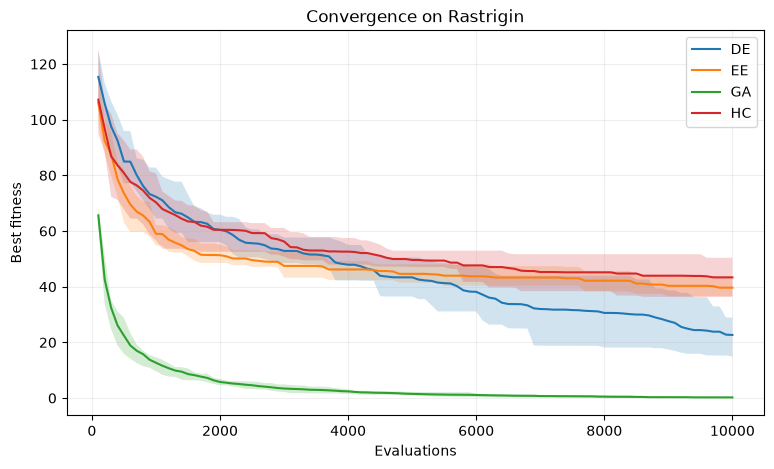

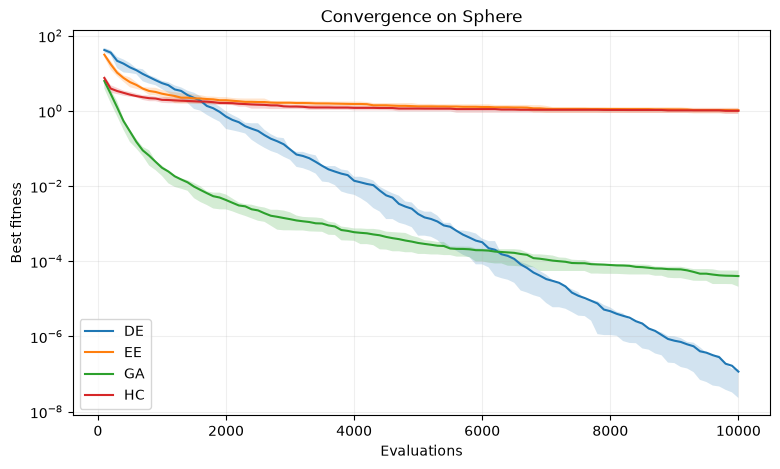

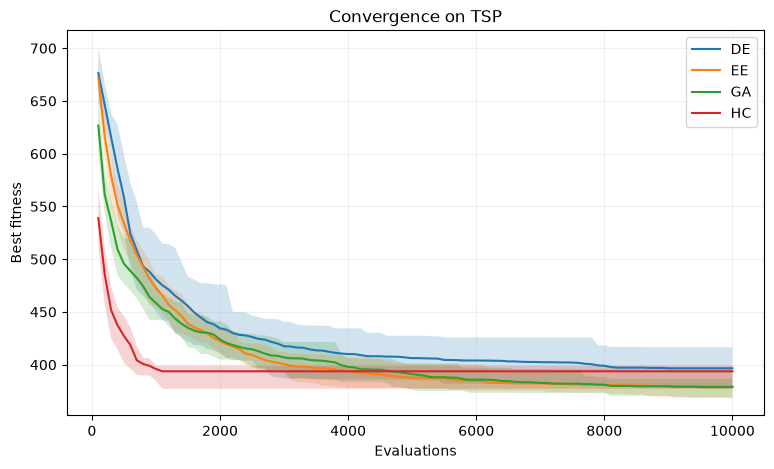

In [21]:
grouped = history_df.groupby(
    ["problem", "algorithm", "evaluation"]
)["best_fitness"]

aggregated = grouped.agg(
    mean="mean",
    q25=lambda values: values.quantile(0.25),
    q75=lambda values: values.quantile(0.75)
).reset_index()

assert len(aggregated) == 1200

for problem_name, problem_data in aggregated.groupby("problem"):

    fig, ax = plt.subplots(figsize=(9, 5))

    for algorithm_name, algorithm_data in problem_data.groupby("algorithm"):

        evaluation = algorithm_data["evaluation"]
        mean = algorithm_data["mean"]
        q25 = algorithm_data["q25"]
        q75 = algorithm_data["q75"]

        ax.plot(
            evaluation,
            mean,
            label=algorithm_name
        )

        ax.fill_between(
            evaluation,
            q25,
            q75,
            alpha=0.2
        )

    ax.set_title(f"Convergence on {problem_name}")
    ax.set_xlabel("Evaluations")
    ax.set_ylabel("Best fitness")
    ax.legend()
    ax.grid(alpha=0.2)

    if problem_name == "Sphere":
        ax.set_yscale("log")

    plt.show()
    plt.close(fig)

## Distribución del fitness final

Los diagramas de caja muestran la distribución del mejor fitness obtenido al finalizar cada una de las 20 ejecuciones independientes. Permiten comparar medianas, dispersión y valores atípicos entre algoritmos.

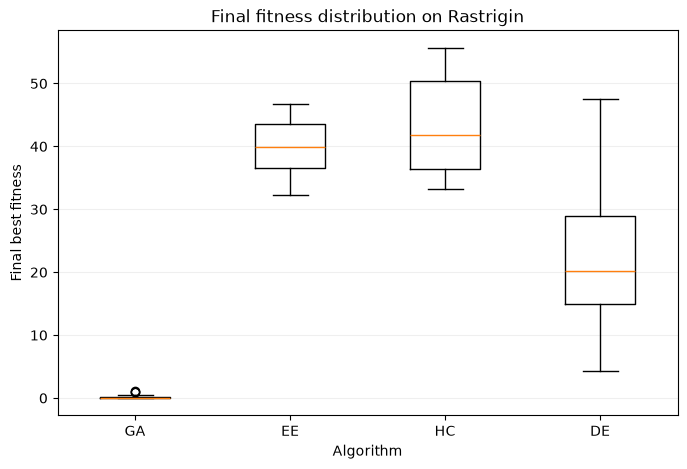

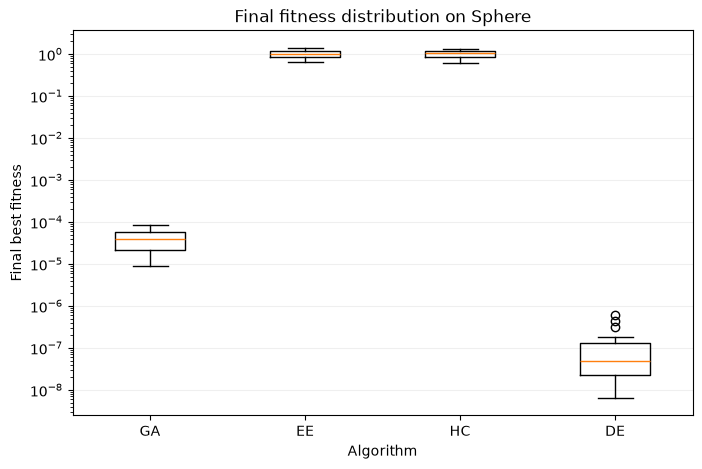

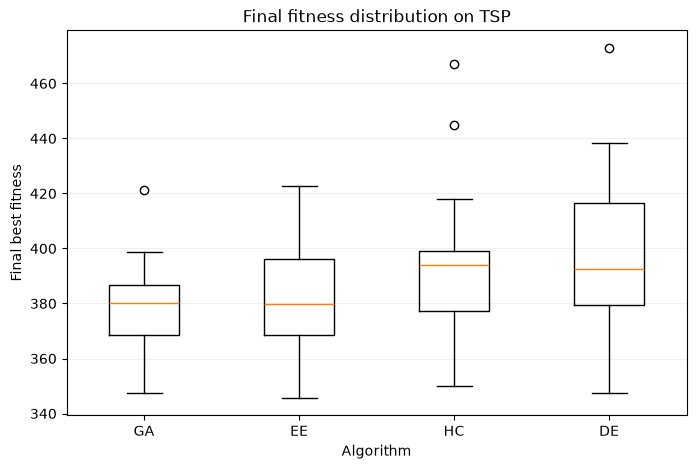

In [22]:
for problem_name, problem_data in runs_df.groupby("problem"):

    fig, ax = plt.subplots(figsize=(8, 5))

    fitness_ga = problem_data.loc[
        problem_data["algorithm"] == "GA",
        "best_fitness"
    ]

    fitness_ee = problem_data.loc[
        problem_data["algorithm"] == "EE",
        "best_fitness"
    ]

    fitness_hc = problem_data.loc[
        problem_data["algorithm"] == "HC",
        "best_fitness"
    ]

    fitness_de = problem_data.loc[
        problem_data["algorithm"] == "DE",
        "best_fitness"
    ]

    ax.boxplot(
        [fitness_ga, fitness_ee, fitness_hc, fitness_de],
        tick_labels=["GA", "EE", "HC", "DE"]
    )

    ax.set_title(
        f"Final fitness distribution on {problem_name}"
    )
    ax.set_xlabel("Algorithm")
    ax.set_ylabel("Final best fitness")

    if problem_name == "Sphere":
        ax.set_yscale("log")

    ax.grid(axis="y", alpha=0.2)

    plt.show()
    plt.close(fig)

## Mejor ruta obtenida para TSP

Se representa el recorrido de menor distancia encontrado entre las ejecuciones de los cuatro algoritmos. La figura muestra las 20 ciudades y el circuito cerrado correspondiente a la mejor solución experimental.

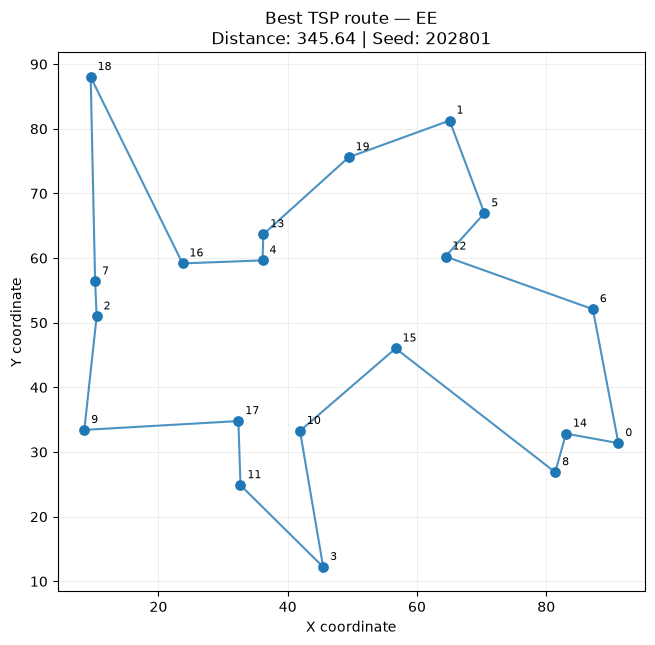

In [23]:
tsp_runs = runs_df[runs_df["problem"] == "TSP"]

best_index = tsp_runs["best_fitness"].idxmin()
best_run = tsp_runs.loc[best_index]

route = np.asarray(
    json.loads(best_run["best_candidate"]),
    dtype=int
)

problem = problems["TSP"]
cities = problem.cities

assert problem.validate(route)
assert np.isclose(
    problem.evaluate(route),
    best_run["best_fitness"]
)

route_coordinates = cities[route]

closed_route = np.vstack([
    route_coordinates,
    route_coordinates[0]
])

Fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    closed_route[:, 0],
    closed_route[:, 1],
    linewidth=1.5,
    alpha=0.8
)

ax.scatter(
    cities[:, 0],
    cities[:, 1],
    s=45,
    zorder=3
)

for i, (x, y) in enumerate(cities):
    ax.annotate(
        str(i),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title(
    f"Best TSP route — {best_run['algorithm']}\n"
    f"Distance: {best_run['best_fitness']:.2f} | "
    f"Seed: {best_run['seed']}"
)

ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)

plt.show()
plt.close(fig)

In [24]:
assert len(runs_df) == 240
assert len(history_df) == 24000

assert runs_df["problem"].nunique() == 3
assert runs_df["algorithm"].nunique() == 4

assert (
    runs_df.groupby(["problem", "algorithm"])["seed"]
    .nunique()
    .eq(20)
    .all()
)

assert (runs_df["evaluations"] == 10000).all()

assert len(friedman_df) == 3
assert len(diversity_df) == 12

print("All benchmark checks passed")

All benchmark checks passed
